# Noisy dynamics: exact targets vs emu-mps vs the Chebyshev trajectory engines

Same physics as `examples/emu_mps/heisenberg.ipynb`, now with the fast exact solvers of `scripts/`:

| Solver | What it is | Error |
|---|---|---|
| **exact state vector** | dense $2^n$ matrix exponentials, piecewise constant drive | round-off |
| **exact Lindblad** | dense density matrix, RK4 on $\dot\rho = -i[H,\rho] + \sum_k L_k\rho L_k^\dagger - \frac12\{L_k^\dagger L_k,\rho\}$ | RK4, $\lesssim 10^{-7}$ here (checked below) |
| **emu-mps** | MPS + TDVP, quantum jumps (one trajectory per run) | truncation, TDVP splitting, $1/\sqrt{N_{traj}}$ |
| **noisy_cheb** (reference engine) | exact quantum trajectories: Chebyshev series of $e^{-iH_{\rm eff}t}$ between jumps, jump times from the interpolated norm | $1/\sqrt{N_{traj}}$ only |
| **noisy_cheb_fast** (optimized engine) | same trajectories, batched in one block, jumps detected at segment ends, Bessel tables cached | identical trajectories to the reference (same random streams) |

All solvers read the same `SequenceData` that emu-base builds from the pulser sequence, so drive samples, couplings and Lindblad operators are identical. Every quantity is compared with the exact target; times are wall-clock seconds on this machine (CPU here: emu-mps and our engines both run on the CPU; on a GPU the gap grows, see the end).

Sections: 1. Heisenberg chain from the XY channel (pulsed and free), noiseless; 2. the same with dephasing + depolarizing noise; 3. an NMR-like spin network: isotropic J-couplings, chemical shifts (DMM detuning map), local RF pulses, $T_1$ / $T_2$ noise, connected correlators; 4. FRESNEL's device noise model (dephasing, relaxation, readout errors); 5. timing summary.

In [1]:
import dataclasses
import logging
import os
import random
import time
import warnings
from scipy.linalg import expm

import matplotlib.pyplot as plt
import numpy as np
import pulser
import torch
from emu_base import HamiltonianType, PulserData
from emu_mps import MPS, BitStrings, CorrelationMatrix, MPSBackend, MPSConfig, Occupation
from pulser.devices import MockDevice
from pulser.register import RegisterLayout

import noisy_cheb
import noisy_cheb_fast
import rydberg_cheb_fast as ryd

warnings.filterwarnings("ignore")
logging.getLogger("emulators").setLevel(logging.WARNING)
random.seed(0)  # emu-mps quantum jumps use python's random
torch.manual_seed(0)
dtype = torch.complex128
DT = 10  # ns
FULL = False  # False: small systems and few emu-mps trajectories (~3 min); True: the n = 6 setup of heisenberg.ipynb (~15 min)
N_MPS, N_REF, N_FAST = (50, 500, 5000) if FULL else (10, 300, 2000)  # trajectories: emu-mps, noisy_cheb, noisy_cheb_fast
N_SPREAD = 50000 if FULL else 20000  # separate noisy_cheb_fast sample, only for the per-trajectory spread (error bars)
plt.rcParams.update({"font.family": ["Avenir Next", "Avenir", "Arial", "sans-serif"], "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "figure.dpi": 110, "figure.constrained_layout.use": True})
EXACT_C, MPS_C, REF_C, FAST_C = "black", "#00B050", "#9DC3E6", "#0070C0"  # exact, emu-mps, reference, fast
TIMINGS = []  # (case, solver, trajectories, seconds)

## Helpers

`exact_dynamics` returns the diagonal of $\rho(t)$ at every time step (state vector: dense exponentials; Lindblad: RK4), with $H$ built from Kronecker products of Pauli matrices out of the `SequenceData`. `run_emu_mps` runs emu-mps trajectory by trajectory (per-trajectory occupations give the error bars). Occupations $\langle n_i\rangle$ and second moments $\langle n_i n_j\rangle$ follow from the diagonal; the connected correlator is $C_{ij} = \langle n_i n_j\rangle - \langle n_i\rangle\langle n_j\rangle$.

In [2]:
def exact_dynamics(sd, initial_bits, lindblad, n_sub=10):
    model = noisy_cheb._Model(sd, torch.device("cpu"))
    n = model.n_total
    op = noisy_cheb._dense_ops(n)
    i0 = int(initial_bits, 2)
    times = np.asarray(sd.target_times, float)
    Ls = [op(L[:2, :2], q) for L in model.lindblad for q in range(n)] if lindblad else []
    LdL = sum((L.conj().T @ L for L in Ls), np.zeros((2 ** n, 2 ** n), complex))
    rho = np.zeros((2 ** n, 2 ** n), complex)
    rho[i0, i0] = 1
    psi = rho[:, i0].copy()
    out = [np.diag(rho).real.copy()]
    for p, (ta, tb, *_) in enumerate(model.pieces):
        H = noisy_cheb._dense_hamiltonian(model, p, model.good)
        steps = [(a, b) for a, b in zip(times, times[1:]) if a >= ta - 1e-9 and b <= tb + 1e-9]
        if not lindblad:
            U = {}
            for a, b in steps:
                if b - a not in U:
                    U[b - a] = expm(-1j * H * (b - a) / 1000)
                psi = U[b - a] @ psi
                out.append(np.abs(psi) ** 2)
            continue
        Heff = H - 0.5j * LdL

        def rhs(r):
            o = -1j * (Heff @ r - r @ Heff.conj().T)
            for L in Ls:
                o += L @ r @ L.conj().T
            return o

        for a, b in steps:
            h = (b - a) / 1000 / n_sub
            for _ in range(n_sub):
                k1 = rhs(rho)
                k2 = rhs(rho + h / 2 * k1)
                k3 = rhs(rho + h / 2 * k2)
                k4 = rhs(rho + h * k3)
                rho = rho + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
            out.append(np.diag(rho).real.copy())
    return np.array(out)


def moments_of(diag, n):
    occ, second = ryd.moments(torch.as_tensor(diag), n)
    return occ.numpy(), second.numpy()


def connected(occ, second):
    return second - occ[..., :, None] * occ[..., None, :]


def run_emu_mps(sd, n_traj, initial_bits, fractions, correlations=False, noise_model=None, shots=0):
    # one MCWF trajectory per call; returns per-trajectory occupations (N, T, n), correlation matrices, bitstrings
    factors = [torch.tensor([[[1.0 - int(b)], [float(b)]]], dtype=dtype) for b in initial_bits]
    observables = [Occupation(evaluation_times=list(fractions))]
    if correlations:
        observables.append(CorrelationMatrix(evaluation_times=[1.0]))
    if shots:
        observables.append(BitStrings(evaluation_times=[1.0], num_shots=shots))
    config = MPSConfig(observables=observables, initial_state=MPS(factors, eigenstates=sd.eigenstates),
                       optimize_qubit_ordering=False, precision=1e-9, log_level=logging.WARNING,
                       noise_model=noise_model)
    occ, corr, bits = [], [], []
    for _ in range(n_traj):
        res = MPSBackend._run_from_sequence_data(sd, config)
        occ.append(torch.stack([torch.as_tensor(o) for o in res.occupation]).real.numpy())
        if correlations:
            corr.append(np.asarray(res.correlation_matrix[-1]).real)
        if shots:
            bits.append(res.bitstrings[-1])
    return np.array(occ), (np.array(corr) if corr else None), bits


def timed(case, solver, n_traj, fn):
    t0 = time.perf_counter()
    out = fn()
    TIMINGS.append((case, solver, n_traj, time.perf_counter() - t0))
    return out


def trajectory_spread(sd, fractions, initial_bits=None):
    # per-trajectory standard deviation of <n_i>(t) from a large separate sample (not timed): every solver samples the
    # same quantum-jump trajectories, and early on population-changing jumps are rare events that a small sample's own
    # spread misses (e.g. 0 bit flips of a qubit among 2000 trajectories at 10 ns)
    occ = noisy_cheb_fast.run_sequence_data([sd] * N_SPREAD, fractions, seed=99, initial_state=initial_bits).occupations
    return occ.numpy().std(0, ddof=1)


def mean_se(x, spread):
    return x.mean(0), spread / np.sqrt(len(x))


def max_z(m, se, target):
    return (np.abs(m - target) / np.maximum(se, 1e-6)).max()

## 1. Heisenberg chain from the XY channel

As in `heisenberg.ipynb`: a chain of atoms (6 with `FULL`, else 4) 18 µm apart on the global microwave channel of `MockDevice`, a **pulsed** sequence (Blackman π pulse, detuning ramp from -3 to 3 rad/µs) and a **free** one (Ω = Δ = 0), the pulser XY couplings replaced by a $3\times n\times n$ stack $[J^{xx}, J^{yy}, J^{zz}] = (1, 0.7, 1.3)\, C_3(1-3\cos^2\theta)/r^3$, Néel initial state.

In [3]:
n, T = (6 if FULL else 4), 1000
reg = pulser.Register.rectangle(1, n, spacing=18.0, prefix="q")
anisotropy = torch.tensor([1.0, 0.7, 1.3], dtype=torch.float64)
neel = "".join(str(j % 2) for j in range(n))


def make_xy_sequence(pulsed):
    seq = pulser.Sequence(reg, MockDevice)
    seq.declare_channel("mw", "mw_global")
    if pulsed:
        seq.add(pulser.Pulse(pulser.BlackmanWaveform(T, area=np.pi), pulser.RampWaveform(T, -3.0, 3.0), 0.0), "mw")
    else:
        seq.delay(T, "mw")
    return seq


def to_heisenberg(sd):
    J = anisotropy[:, None, None] * sd.interaction_matrix(0.0)[0].real.double()
    return dataclasses.replace(sd, interaction_matrix=lambda t: J)  # 3 x n x n => Heisenberg


def sequence_data(seq, noise_model=None, replace=to_heisenberg):
    cfg = MPSConfig(dt=DT, noise_model=noise_model) if noise_model else MPSConfig(dt=DT)
    (sd,) = PulserData(sequence=seq, config=cfg, dt=DT).get_sequences()
    return replace(sd) if replace else sd


sequences = {"pulsed": make_xy_sequence(True), "free": make_xy_sequence(False)}
sds = {name: sequence_data(seq) for name, seq in sequences.items()}
fractions = np.linspace(0, 1, len(sds["pulsed"].target_times))  # every time step
times_ns = np.asarray(sds["pulsed"].target_times, float)
print(f"nearest-neighbour Jxx = {sds['pulsed'].interaction_matrix(0)[0, 0, 1]:.3f} rad/us, {len(times_ns) - 1} steps of {DT} ns")

nearest-neighbour Jxx = 6.222 rad/us, 100 steps of 10 ns


In [4]:
exact1, mps1, ref1, fast1 = {}, {}, {}, {}
for name, sd in sds.items():
    exact1[name] = moments_of(timed(f"1 {name}", "exact state vector", 1, lambda: exact_dynamics(sd, neel, False)), n)[0]
    mps1[name] = timed(f"1 {name}", "emu-mps", 1, lambda: run_emu_mps(sd, 1, neel, fractions)[0][0])
    ref1[name] = timed(f"1 {name}", "noisy_cheb", 1,
                       lambda: noisy_cheb.run_sequence_data([sd], fractions, initial_state=neel).occupations[0].numpy())
    fast1[name] = timed(f"1 {name}", "noisy_cheb_fast", 1,
                        lambda: noisy_cheb_fast.run_sequence_data([sd], fractions, initial_state=neel).occupations[0].numpy())
    print(f"{name:>6}: max |<n_j> - exact|: emu-mps {np.abs(mps1[name] - exact1[name]).max():.1e}, "
          f"noisy_cheb {np.abs(ref1[name] - exact1[name]).max():.1e}, noisy_cheb_fast {np.abs(fast1[name] - exact1[name]).max():.1e}")

pulsed: max |<n_j> - exact|: emu-mps 1.4e-04, noisy_cheb 2.1e-15, noisy_cheb_fast 2.4e-15


  free: max |<n_j> - exact|: emu-mps 1.3e-03, noisy_cheb 7.1e-15, noisy_cheb_fast 6.9e-15


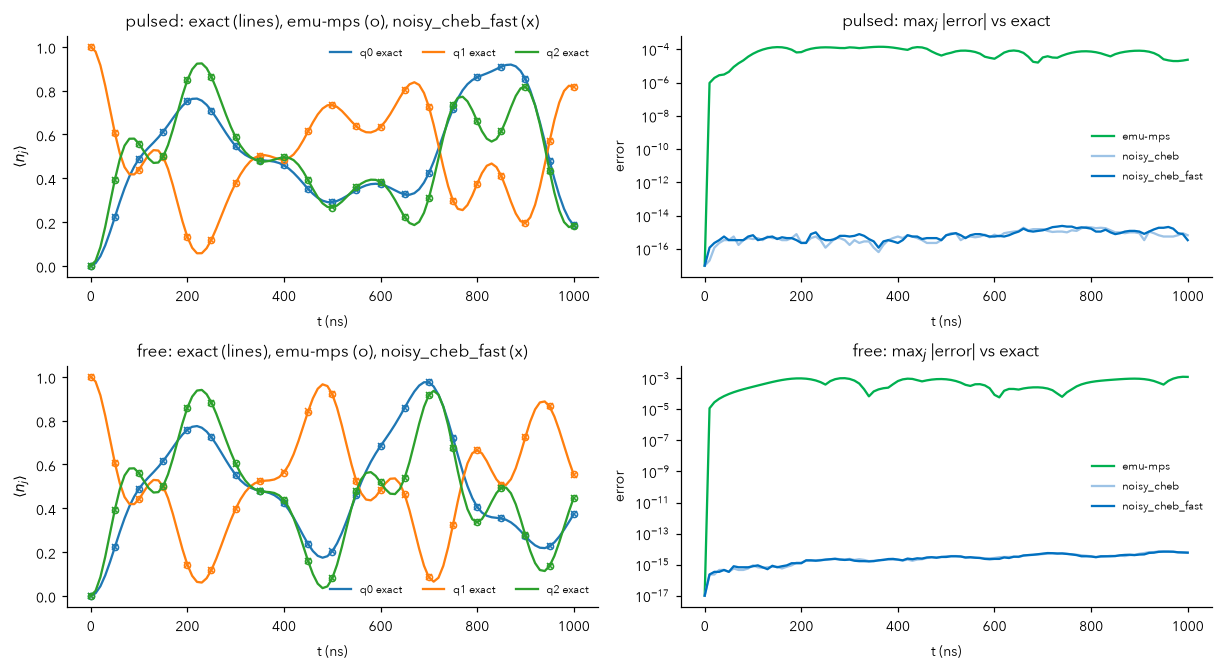

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for row, name in zip(axes, sds):
    for j, c in zip((0, 1, 2), ("C0", "C1", "C2")):
        row[0].plot(times_ns, exact1[name][:, j], color=c, lw=1.5, label=f"q{j} exact")
        row[0].plot(times_ns[::5], mps1[name][::5, j], "o", color=c, ms=4, mfc="none")
        row[0].plot(times_ns[::5], fast1[name][::5, j], "x", color=c, ms=4)
    row[0].set(title=f"{name}: exact (lines), emu-mps (o), noisy_cheb_fast (x)", xlabel="t (ns)", ylabel=r"$\langle n_j\rangle$")
    row[0].legend(fontsize=7, ncol=3)
    for label, occ, c in (("emu-mps", mps1, MPS_C), ("noisy_cheb", ref1, REF_C), ("noisy_cheb_fast", fast1, FAST_C)):
        row[1].semilogy(times_ns, np.abs(occ[name] - exact1[name]).max(1) + 1e-17, color=c, label=label)
    row[1].set(title=f"{name}: max$_j$ |error| vs exact", xlabel="t (ns)", ylabel="error")
    row[1].legend(fontsize=7)
plt.show()

Our engines are exact to round-off; emu-mps carries its TDVP splitting error from the long-range $1/r^3$ couplings (it scales as $dt^2$, see `heisenberg.ipynb`). The single noiseless runs are not a speed test at this size: a trajectory with an output every 10 ns costs ~0.1 s of Python overhead in our engines (one series per output interval), ~1 s in emu-mps.

## 2. The same with noise: dephasing 0.2 /µs + depolarizing 0.1 /µs

Exact Lindblad as the target. Error bars and z-scores use the per-trajectory spread of $\langle n_i\rangle(t)$ estimated once from a large separate sample (`N_SPREAD` noisy_cheb_fast trajectories, not timed), divided by $\sqrt{N}$ of each solver: all solvers sample the same quantum-jump trajectories, and at early times population-changing jumps are rare events that a small sample's own spread misses. Trajectories: emu-mps 50 / noisy_cheb 500 / noisy_cheb_fast 5000 with `FULL` (as `heisenberg.ipynb` for emu-mps), else 10 / 300 / 2000. Error bars: standard error over trajectories. First, the RK4 target is checked against the exact state vector in the noiseless limit.

In [6]:
rk4 = moments_of(exact_dynamics(sds["pulsed"], neel, True), n)[0]
print(f"RK4 target, noiseless limit: max |<n_j> - exact state vector| = {np.abs(rk4 - exact1['pulsed']).max():.1e}")

noise = pulser.NoiseModel(dephasing_rate=0.2, depolarizing_rate=0.1)
noisy = {}
for name, seq in sequences.items():
    sd = sequence_data(seq, noise)
    case = f"2 {name}"
    target = moments_of(timed(case, "exact Lindblad (RK4)", 1, lambda: exact_dynamics(sd, neel, True)), n)[0]
    mps = timed(case, "emu-mps", N_MPS, lambda: run_emu_mps(sd, N_MPS, neel, fractions)[0])
    ref = timed(case, "noisy_cheb", N_REF,
                lambda: noisy_cheb.run_sequence_data([sd] * N_REF, fractions, seed=1, initial_state=neel).occupations.numpy())
    fast = timed(case, "noisy_cheb_fast", N_FAST,
                 lambda: noisy_cheb_fast.run_sequence_data([sd] * N_FAST, fractions, seed=2, initial_state=neel).occupations.numpy())
    spread = trajectory_spread(sd, fractions, neel)
    noisy[name] = dict(target=target, mps=mean_se(mps, spread), ref=mean_se(ref, spread), fast=mean_se(fast, spread))
    for label in ("mps", "ref", "fast"):
        m, se = noisy[name][label]
        print(f"{name:>6} {label:5s}: max |<n_j> - Lindblad| {np.abs(m - target).max():.4f}, max z {max_z(m, se, target):.1f}")
    print(f"{name:>6}: noise effect max |Lindblad - noiseless| = {np.abs(target - exact1[name]).max():.3f}")

RK4 target, noiseless limit: max |<n_j> - exact state vector| = 2.1e-07


pulsed mps  : max |<n_j> - Lindblad| 0.0780, max z 2.0
pulsed ref  : max |<n_j> - Lindblad| 0.0131, max z 3.1
pulsed fast : max |<n_j> - Lindblad| 0.0080, max z 3.1
pulsed: noise effect max |Lindblad - noiseless| = 0.185


  free mps  : max |<n_j> - Lindblad| 0.1151, max z 2.4
  free ref  : max |<n_j> - Lindblad| 0.0225, max z 3.1
  free fast : max |<n_j> - Lindblad| 0.0082, max z 2.7
  free: noise effect max |Lindblad - noiseless| = 0.184


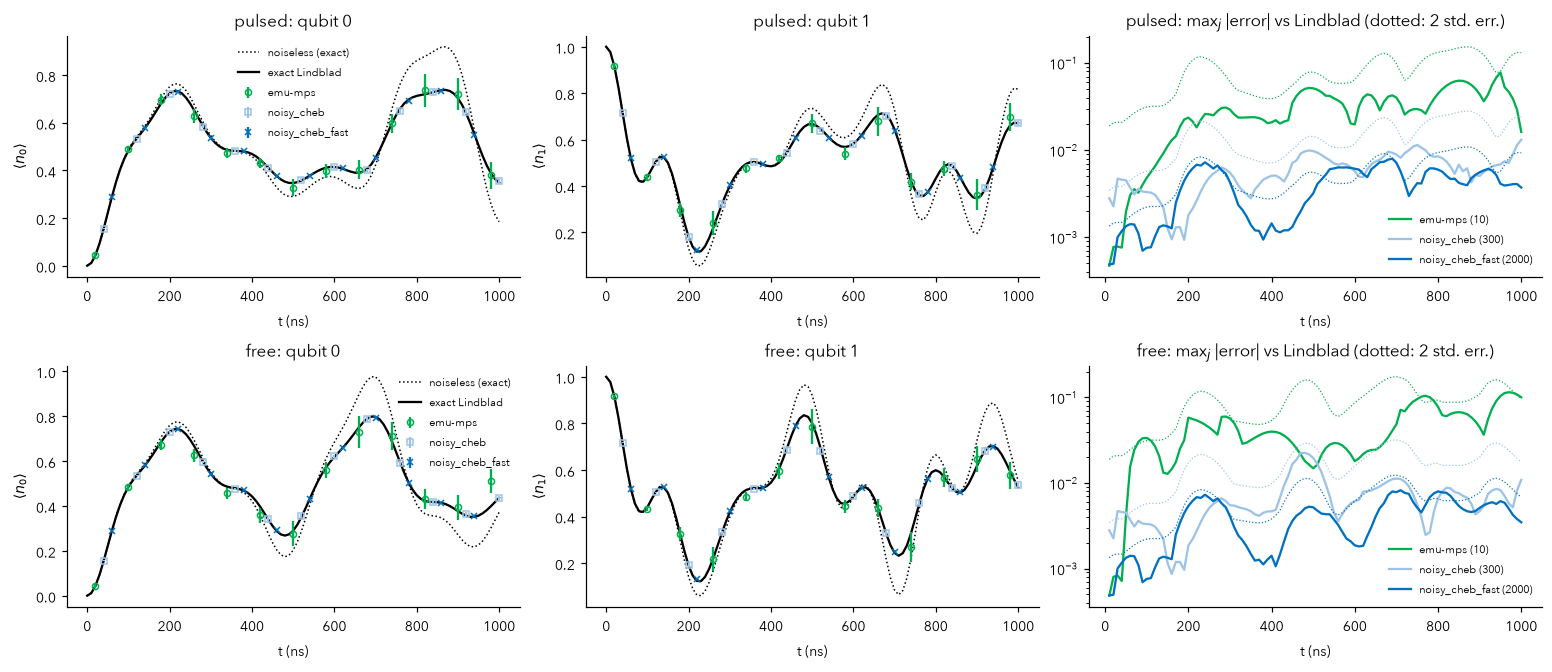

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for row, name in zip(axes, noisy):
    r = noisy[name]
    for ax, j in zip(row[:2], (0, 1)):
        ax.plot(times_ns, exact1[name][:, j], "k:", lw=1, label="noiseless (exact)")
        ax.plot(times_ns, r["target"][:, j], color=EXACT_C, lw=1.5, label="exact Lindblad")
        for label, key, c, fmt, s in (("emu-mps", "mps", MPS_C, "o", slice(2, None, 8)),
                                      ("noisy_cheb", "ref", REF_C, "s", slice(4, None, 8)),
                                      ("noisy_cheb_fast", "fast", FAST_C, "x", slice(6, None, 8))):
            m, se = r[key]
            ax.errorbar(times_ns[s], m[s, j], yerr=se[s, j], fmt=fmt, color=c, ms=4, mfc="none", label=label)
        ax.set(title=f"{name}: qubit {j}", xlabel="t (ns)", ylabel=rf"$\langle n_{j}\rangle$")
    row[0].legend(fontsize=7)
    for label, key, c in ((f"emu-mps ({N_MPS})", "mps", MPS_C), (f"noisy_cheb ({N_REF})", "ref", REF_C), (f"noisy_cheb_fast ({N_FAST})", "fast", FAST_C)):
        m, se = r[key]
        row[2].semilogy(times_ns[1:], np.abs(m - r["target"]).max(1)[1:], color=c, label=label)
        row[2].semilogy(times_ns[1:], 2 * se.max(1)[1:], color=c, ls=":", lw=0.8)
    row[2].set(title=f"{name}: max$_j$ |error| vs Lindblad (dotted: 2 std. err.)", xlabel="t (ns)")
    row[2].legend(fontsize=7)
plt.show()

## 3. NMR-like spin network with local control

Five spins (four without `FULL`) with **isotropic scalar couplings** $J_{ij}(X_iX_j + Y_iY_j + Z_iZ_j)$ on a chain plus one long-range bond (no geometric $1/r^3$ or $1/r^6$ profile: the $3\times n\times n$ stack is set directly), **chemical shifts** from a DMM detuning map (a different static detuning per spin), **local RF pulses** on the `rydberg_local` channel: a $\pi/2$ pulse on q0, then a $\pi$ pulse with phase $\pi/2$ on q3, then free evolution under the couplings. Noise: relaxation 0.3 /µs ($T_1$-like) and dephasing 0.5 /µs ($T_2$-like). Initial state $|00000\rangle$.

Besides $\langle n_i\rangle(t)$ we compare the final **connected correlators** $C_{ij} = \langle n_in_j\rangle - \langle n_i\rangle\langle n_j\rangle$.

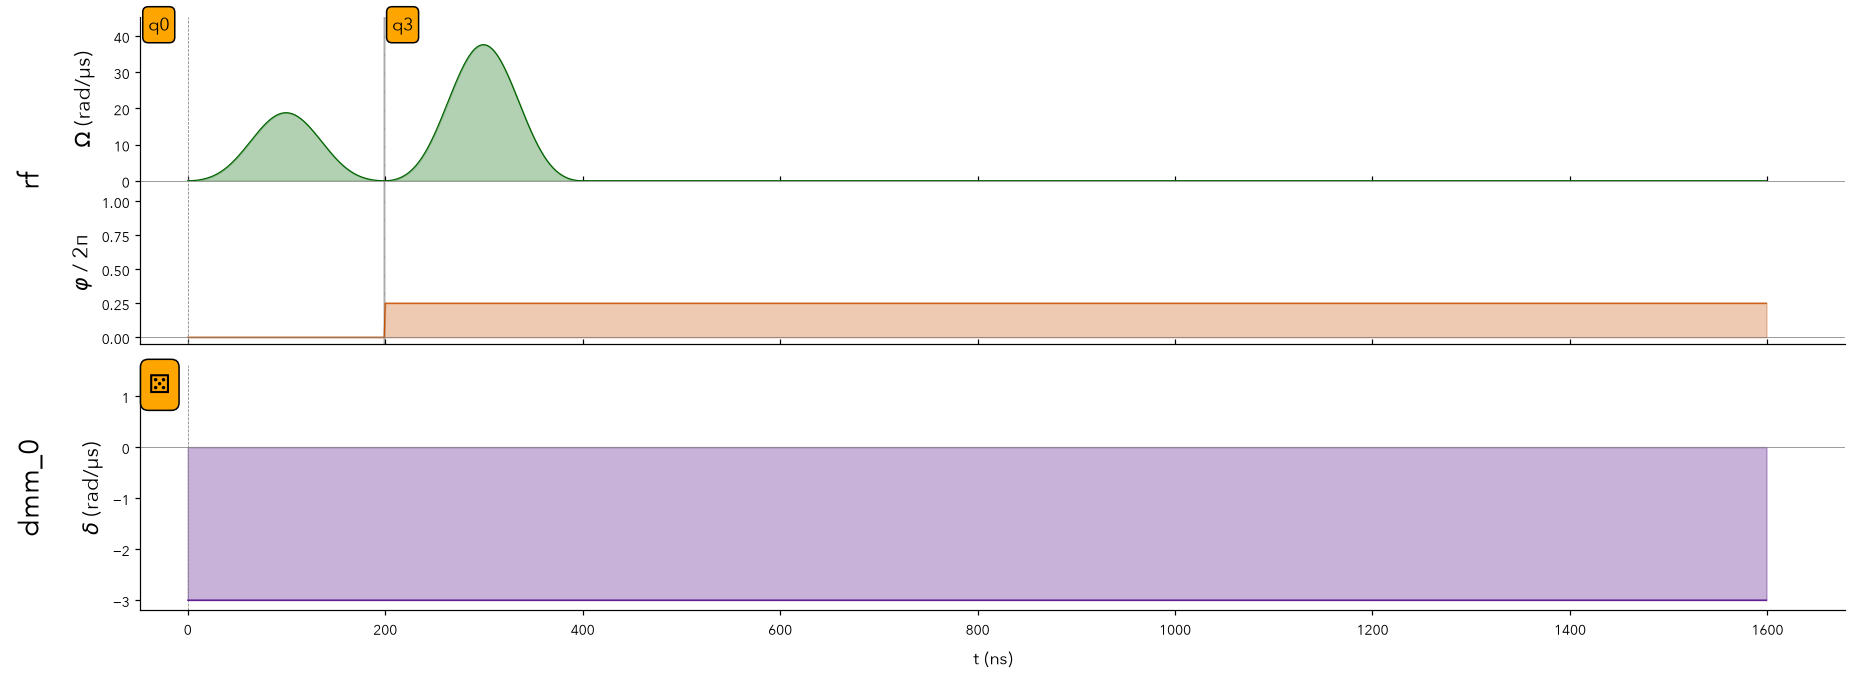

In [8]:
n_nmr = 5 if FULL else 4
layout = RegisterLayout([[6.0 * k, 0.0] for k in range(2 * n_nmr)])
reg_nmr = layout.define_register(*range(n_nmr), qubit_ids=[f"q{i}" for i in range(n_nmr)])
T_nmr = 1600
seq_nmr = pulser.Sequence(reg_nmr, MockDevice)
seq_nmr.declare_channel("rf", "rydberg_local", initial_target="q0")
shifts = {f"q{i}": s for i, s in enumerate([1.0, 0.55, 0.25, 0.8, 0.0][:n_nmr])}  # relative chemical shifts
seq_nmr.config_detuning_map(reg_nmr.define_detuning_map(shifts), "dmm_0")
seq_nmr.add(pulser.Pulse(pulser.BlackmanWaveform(200, np.pi / 2), pulser.ConstantWaveform(200, 0.0), 0.0), "rf")
seq_nmr.target("q3", "rf")
seq_nmr.add(pulser.Pulse(pulser.BlackmanWaveform(200, np.pi), pulser.ConstantWaveform(200, 0.0), np.pi / 2), "rf")
seq_nmr.delay(T_nmr - 400, "rf")
# chemical shifts during the whole sequence (no-delay: overlaps the RF pulses instead of waiting for them)
seq_nmr.add_dmm_detuning(pulser.ConstantWaveform(T_nmr, -3.0), "dmm_0", protocol="no-delay")  # delta_i = -3 x shift_i

J_nmr = np.zeros((n_nmr, n_nmr))
for i, j, v in [(0, 1, 1.2), (1, 2, 0.7), (2, 3, 1.5), (3, 4, 0.9), (0, 2, 0.3)]:  # rad/us
    if j < n_nmr:
        J_nmr[i, j] = J_nmr[j, i] = v
J3_nmr = torch.as_tensor(np.stack([J_nmr] * 3))


def to_nmr(sd):
    return dataclasses.replace(sd, interaction_matrix=lambda t: J3_nmr, hamiltonian_type=HamiltonianType.XY)


ground = "0" * n_nmr
noise_nmr = pulser.NoiseModel(relaxation_rate=0.3, dephasing_rate=0.5)
sd_nmr_clean = sequence_data(seq_nmr, None, to_nmr)
sd_nmr = sequence_data(seq_nmr, noise_nmr, to_nmr)
fr_nmr = np.linspace(0, 1, len(sd_nmr.target_times))
t_nmr = np.asarray(sd_nmr.target_times, float)
seq_nmr.draw()

In [9]:
case = "3 NMR"
clean = moments_of(exact_dynamics(sd_nmr_clean, ground, False), n_nmr)
diag_t = timed(case, "exact Lindblad (RK4)", 1, lambda: exact_dynamics(sd_nmr, ground, True))
target, target_second = moments_of(diag_t, n_nmr)
occ_m, corr_m, _ = timed(case, "emu-mps", N_MPS, lambda: run_emu_mps(sd_nmr, N_MPS, ground, fr_nmr, correlations=True))
res_ref = timed(case, "noisy_cheb", N_REF, lambda: noisy_cheb.run_sequence_data([sd_nmr] * N_REF, fr_nmr, seed=3))
res_fast = timed(case, "noisy_cheb_fast", N_FAST, lambda: noisy_cheb_fast.run_sequence_data([sd_nmr] * N_FAST, fr_nmr, seed=4))
spread = trajectory_spread(sd_nmr, fr_nmr)
nmr = dict(mps=mean_se(occ_m, spread), ref=mean_se(res_ref.occupations.numpy(), spread),
           fast=mean_se(res_fast.occupations.numpy(), spread))
for label, (m, se) in nmr.items():
    print(f"{label:5s}: max |<n_i> - Lindblad| {np.abs(m - target).max():.4f}, max z {max_z(m, se, target):.1f}")
print(f"noise effect max |Lindblad - noiseless| = {np.abs(target - clean[0]).max():.3f}")
C_exact = connected(target[-1], target_second[-1])
C_fast = connected(res_fast.occupations.numpy().mean(0)[-1], res_fast.correlations.numpy()[-1])
C_mps = connected(occ_m.mean(0)[-1], corr_m.mean(0))
print(f"connected correlators at {T_nmr} ns: max |C_fast - C_exact| {np.abs(C_fast - C_exact).max():.4f}, "
      f"max |C_emu-mps - C_exact| {np.abs(C_mps - C_exact).max():.4f}, max |C_exact| {np.abs(C_exact).max():.4f}")

mps  : max |<n_i> - Lindblad| 0.1621, max z 4.0
ref  : max |<n_i> - Lindblad| 0.0186, max z 2.3
fast : max |<n_i> - Lindblad| 0.0068, max z 2.6
noise effect max |Lindblad - noiseless| = 0.264
connected correlators at 1600 ns: max |C_fast - C_exact| 0.0032, max |C_emu-mps - C_exact| 0.0426, max |C_exact| 0.2191


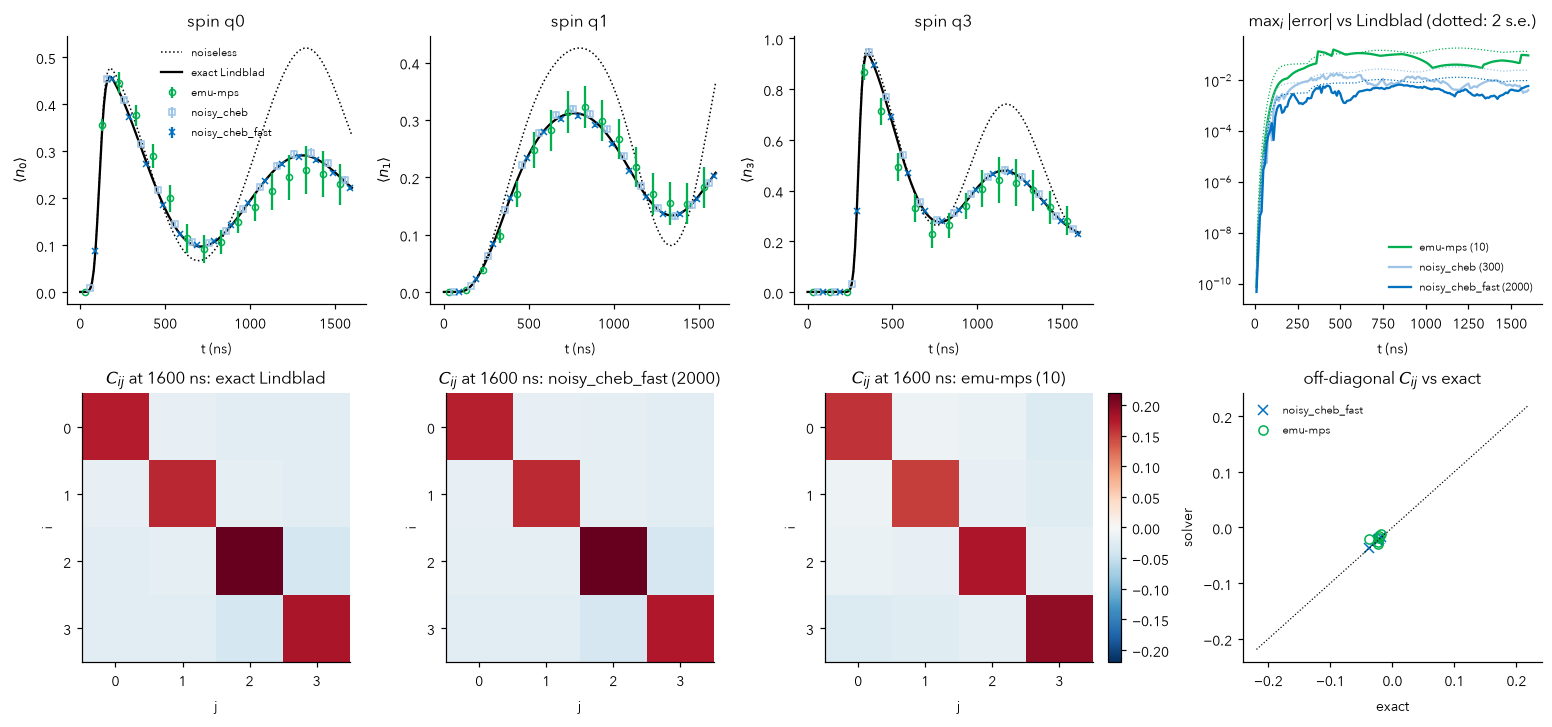

In [10]:
fig = plt.figure(figsize=(14, 6.5))
gs = fig.add_gridspec(2, 4)
for k, j in enumerate((0, 1, 3)):
    ax = fig.add_subplot(gs[0, k])
    ax.plot(t_nmr, clean[0][:, j], "k:", lw=1, label="noiseless")
    ax.plot(t_nmr, target[:, j], color=EXACT_C, lw=1.5, label="exact Lindblad")
    for label, key, c, fmt, s in (("emu-mps", "mps", MPS_C, "o", slice(3, None, 10)),
                                  ("noisy_cheb", "ref", REF_C, "s", slice(6, None, 10)),
                                  ("noisy_cheb_fast", "fast", FAST_C, "x", slice(9, None, 10))):
        m, se = nmr[key]
        ax.errorbar(t_nmr[s], m[s, j], yerr=se[s, j], fmt=fmt, color=c, ms=4, mfc="none", label=label)
    ax.set(title=f"spin q{j}", xlabel="t (ns)", ylabel=rf"$\langle n_{j}\rangle$")
    if k == 0:
        ax.legend(fontsize=7)
ax = fig.add_subplot(gs[0, 3])
for label, key, c in ((f"emu-mps ({N_MPS})", "mps", MPS_C), (f"noisy_cheb ({N_REF})", "ref", REF_C), (f"noisy_cheb_fast ({N_FAST})", "fast", FAST_C)):
    m, se = nmr[key]
    ax.semilogy(t_nmr[1:], np.abs(m - target).max(1)[1:], color=c, label=label)
    ax.semilogy(t_nmr[1:], 2 * se.max(1)[1:], color=c, ls=":", lw=0.8)
ax.set(title="max$_i$ |error| vs Lindblad (dotted: 2 s.e.)", xlabel="t (ns)")
ax.legend(fontsize=7)
vmax = np.abs(C_exact).max()
for k, (title, C) in enumerate((("exact Lindblad", C_exact), (f"noisy_cheb_fast ({N_FAST})", C_fast), (f"emu-mps ({N_MPS})", C_mps))):
    ax = fig.add_subplot(gs[1, k])
    im = ax.imshow(C, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set(title=f"$C_{{ij}}$ at {T_nmr} ns: {title}", xlabel="j", ylabel="i",
           xticks=range(n_nmr), yticks=range(n_nmr))
fig.colorbar(im, ax=ax)
ax = fig.add_subplot(gs[1, 3])
iu = np.triu_indices(n_nmr, 1)
ax.plot(C_exact[iu], C_fast[iu], "x", color=FAST_C, label="noisy_cheb_fast")
ax.plot(C_exact[iu], C_mps[iu], "o", color=MPS_C, mfc="none", label="emu-mps")
ax.plot([-vmax, vmax], [-vmax, vmax], "k:", lw=0.8)
ax.set(title="off-diagonal $C_{ij}$ vs exact", xlabel="exact", ylabel="solver")
ax.legend(fontsize=7)
plt.show()

## 4. FRESNEL's device noise model

The noise model of the FRESNEL QPU spec (fetched from Pasqal Cloud; dephasing, relaxation, SPAM readout errors), on a Rydberg chain 6 µm apart (6 atoms and a 4 µs constant pulse with `FULL`, else 4 atoms and 2 µs). Readout errors only affect sampled bitstrings: we compare $\langle n_i\rangle(t)$ (no readout) and the measured bitstring distribution (with readout) against the exact Lindblad solution passed through the same readout channel. Skipped if the spec file is not available (`FRESNEL_SPECS`, default `~/.cache/pasqal/fresnel_specs.json`).

In [11]:
spec = os.environ.get("FRESNEL_SPECS", os.path.expanduser("~/.cache/pasqal/fresnel_specs.json"))
HAVE_FRESNEL = os.path.exists(spec)
if HAVE_FRESNEL:
    fresnel = pulser.devices.Device.from_abstract_repr(open(spec).read())
    nm_f = fresnel.default_noise_model
    print("FRESNEL noise:", nm_f.noise_types, f"dephasing {nm_f.dephasing_rate:.3f}, relaxation {nm_f.relaxation_rate}, "
          f"p_false_pos {nm_f.p_false_pos}, p_false_neg {nm_f.p_false_neg}")
    n_f, T_f = (6, 4000) if FULL else (4, 2000)
    reg_f = pulser.Register.from_coordinates([(6.0 * k, 0) for k in range(n_f)], prefix="q").with_automatic_layout(fresnel)
    seq_f = pulser.Sequence(reg_f, fresnel)
    seq_f.declare_channel("r", "rydberg_global")
    seq_f.add(pulser.Pulse.ConstantPulse(T_f, 2 * np.pi, 3.0, 0.0), "r")
    sd_f = sequence_data(seq_f, nm_f, None)
    every = 10
    fr_f = np.linspace(0, 1, len(sd_f.target_times))[::every]
    t_f = np.asarray(sd_f.target_times, float)[::every]
    zeros_f = "0" * n_f
else:
    print("FRESNEL spec not found: section skipped")

FRESNEL noise: ('SPAM', 'dephasing', 'relaxation') dephasing 0.222, relaxation 0.01, p_false_pos 0.15, p_false_neg 0.06


In [12]:
if HAVE_FRESNEL:
    case = "4 FRESNEL"
    N_MPS_F = 30 if FULL else 10
    clean_f = moments_of(exact_dynamics(sequence_data(seq_f, None, None), zeros_f, False), n_f)[0][::every]
    diag_f = timed(case, "exact Lindblad (RK4)", 1, lambda: exact_dynamics(sd_f, zeros_f, True))
    target_f = moments_of(diag_f, n_f)[0][::every]
    occ_mf, _, bits_mf = timed(case, "emu-mps", N_MPS_F, lambda: run_emu_mps(sd_f, N_MPS_F, zeros_f, fr_f, noise_model=nm_f, shots=1000))
    res_rf = timed(case, "noisy_cheb", N_REF, lambda: noisy_cheb.run_sequence_data([sd_f] * N_REF, fr_f, seed=5))
    res_ff = timed(case, "noisy_cheb_fast", N_FAST, lambda: noisy_cheb_fast.run_sequence_data([sd_f] * N_FAST, fr_f, seed=6))
    spread = trajectory_spread(sd_f, fr_f)
    fres = dict(mps=mean_se(occ_mf, spread), ref=mean_se(res_rf.occupations.numpy(), spread),
                fast=mean_se(res_ff.occupations.numpy(), spread))
    for label, (m, se) in fres.items():
        print(f"{label:5s}: max |<n_i> - Lindblad| {np.abs(m - target_f).max():.4f}, max z {max_z(m, se, target_f):.1f}")
    print(f"noise effect max |Lindblad - noiseless| = {np.abs(target_f - clean_f).max():.3f}")
    p_exact = noisy_cheb.readout(torch.as_tensor(diag_f[-1]), nm_f.p_false_pos, nm_f.p_false_neg).numpy()
    p_fast = noisy_cheb.readout(res_ff.probabilities[-1], nm_f.p_false_pos, nm_f.p_false_neg).numpy()
    counts = np.array([[c.get(format(x, f"0{n_f}b"), 0) for x in range(2 ** n_f)] for c in bits_mf], float)
    freq = counts / counts.sum(1, keepdims=True)
    f_mps, f_se = freq.mean(0), freq.std(0, ddof=1) / np.sqrt(len(freq))  # rough with few trajectories
    print(f"bitstrings with readout errors: max |p_fast - p_exact| {np.abs(p_fast - p_exact).max():.4f}, "
          f"max |p_emu-mps - p_exact| {np.abs(f_mps - p_exact).max():.4f} (emu-mps std. err. up to {f_se.max():.3f}); "
          f"readout changes P by up to {np.abs(p_exact - diag_f[-1]).max():.3f}")

mps  : max |<n_i> - Lindblad| 0.0616, max z 2.2
ref  : max |<n_i> - Lindblad| 0.0193, max z 2.9
fast : max |<n_i> - Lindblad| 0.0051, max z 2.3
noise effect max |Lindblad - noiseless| = 0.073
bitstrings with readout errors: max |p_fast - p_exact| 0.0015, max |p_emu-mps - p_exact| 0.0332 (emu-mps std. err. up to 0.040); readout changes P by up to 0.151


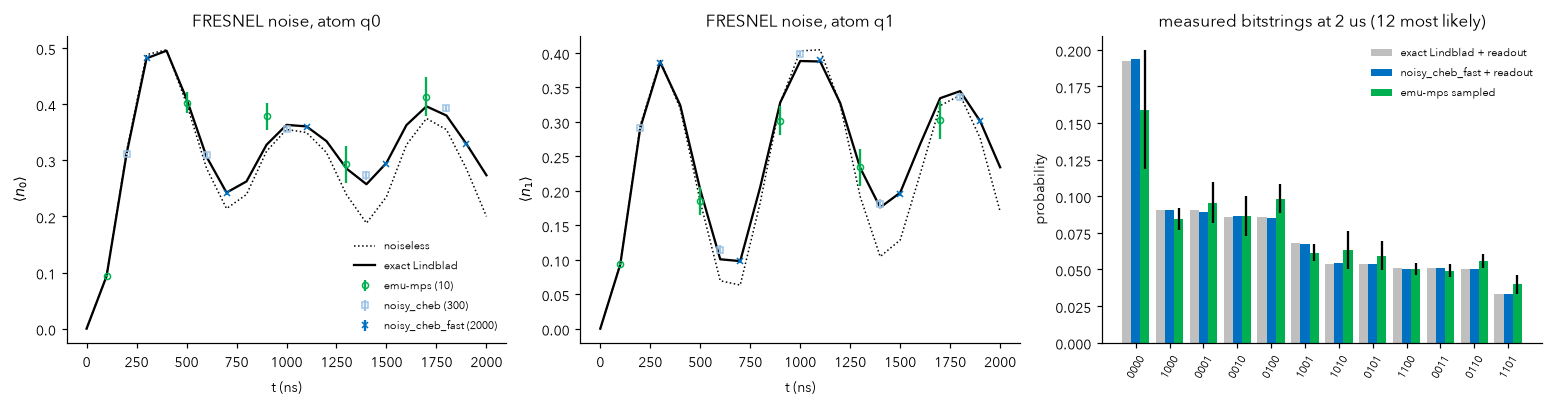

In [13]:
if HAVE_FRESNEL:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    for ax, j in zip(axes[:2], (0, 1)):
        ax.plot(t_f, clean_f[:, j], "k:", lw=1, label="noiseless")
        ax.plot(t_f, target_f[:, j], color=EXACT_C, lw=1.5, label="exact Lindblad")
        for label, key, c, fmt, s in ((f"emu-mps ({N_MPS_F})", "mps", MPS_C, "o", slice(1, None, 4)),
                                      (f"noisy_cheb ({N_REF})", "ref", REF_C, "s", slice(2, None, 4)),
                                      (f"noisy_cheb_fast ({N_FAST})", "fast", FAST_C, "x", slice(3, None, 4))):
            m, se = fres[key]
            ax.errorbar(t_f[s], m[s, j], yerr=se[s, j], fmt=fmt, color=c, ms=4, mfc="none", label=label)
        ax.set(title=f"FRESNEL noise, atom q{j}", xlabel="t (ns)", ylabel=rf"$\langle n_{j}\rangle$")
    axes[0].legend(fontsize=7)
    top = np.argsort(p_exact)[::-1][:12]
    x = np.arange(len(top))
    axes[2].bar(x - 0.27, p_exact[top], 0.27, color="#BFBFBF", label="exact Lindblad + readout")
    axes[2].bar(x, p_fast[top], 0.27, color=FAST_C, label="noisy_cheb_fast + readout")
    axes[2].bar(x + 0.27, f_mps[top], 0.27, yerr=f_se[top], color=MPS_C, label="emu-mps sampled")
    axes[2].set_xticks(x, [format(k, f"0{n_f}b") for k in top], rotation=60, fontsize=7)
    axes[2].set(title=f"measured bitstrings at {T_f / 1000:g} us (12 most likely)", ylabel="probability")
    axes[2].legend(fontsize=7)
    plt.show()

## 5. Timing summary

Wall-clock seconds on this machine (CPU, single process). "per trajectory" divides by the number of trajectories; the speed-up compares noisy_cheb_fast with emu-mps per trajectory. On the A100 (separate runs): FRESNEL noise, 4 µs, the reference engine takes 0.29 / 0.46 / 1.96 s per trajectory at n = 12 / 16 / 20 against 116 / 172 / 241 s for emu-mps, and the fast engine 5-9 ms per trajectory at n = 8-12 (2 µs) against 34-62 s.

In [14]:
print(f"{'case':12s} {'solver':22s} {'traj':>6s} {'total (s)':>10s} {'per traj (ms)':>14s}")
for case, solver, n_traj, sec in TIMINGS:
    print(f"{case:12s} {solver:22s} {n_traj:6d} {sec:10.2f} {sec / n_traj * 1e3:14.2f}")
print()
cases = sorted({c for c, *_ in TIMINGS})
for case in cases:
    per = {s: sec / nt for c, s, nt, sec in TIMINGS if c == case}
    if "emu-mps" in per and "noisy_cheb_fast" in per:
        print(f"{case:12s} noisy_cheb_fast is {per['emu-mps'] / per['noisy_cheb_fast']:8.0f}x faster than emu-mps per trajectory, "
              f"{per['noisy_cheb'] / per['noisy_cheb_fast']:6.0f}x faster than noisy_cheb")

case         solver                   traj  total (s)  per traj (ms)
1 pulsed     exact state vector          1       0.12         124.27
1 pulsed     emu-mps                     1       1.28        1282.04
1 pulsed     noisy_cheb                  1       0.20         197.48
1 pulsed     noisy_cheb_fast             1       0.14         141.46
1 free       exact state vector          1       0.00           2.29
1 free       emu-mps                     1       0.86         864.73
1 free       noisy_cheb                  1       0.16         156.74
1 free       noisy_cheb_fast             1       0.11         114.61
2 pulsed     exact Lindblad (RK4)        1       0.52         517.98
2 pulsed     emu-mps                    10      12.03        1203.10
2 pulsed     noisy_cheb                300      57.67         192.24
2 pulsed     noisy_cheb_fast          2000       2.31           1.15
2 free       exact Lindblad (RK4)        1       0.36         357.00
2 free       emu-mps              

**Reading the results.** In every section the trajectory averages of the two Chebyshev engines follow the exact target within their statistical error, which shrinks as $1/\sqrt{N_{traj}}$; with the same budget of wall-clock time they run 100-1000 times more trajectories than emu-mps, hence the much smaller error bars. Without noise they are exact to round-off, while emu-mps carries its TDVP / truncation error. The connected correlators of the NMR-like network, small here, are reproduced within the statistical error of each method.